# Level 3 · Task 1 — Predictive Modeling
**Cognifyz Data Science Internship**

**Goal:** build regression models that predict a restaurant's `Aggregate rating`, split the data into
training and test sets, evaluate with appropriate metrics, and compare several algorithms.

**Key design decisions (explained where they are applied):**
1. `Rating color` and `Rating text` are excluded — they are direct encodings of the target (leakage).
2. Restaurants with rating `0` are *Not rated* (no rating exists), so the main models are trained on **rated restaurants only**; a sensitivity check including them is run at the end.
3. All preprocessing lives inside an sklearn `Pipeline`, fitted on training data only.
4. Models are selected with cross-validation on the training set; the test set is used once for the final report.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
DATA_PATH = Path("../dataset/Dataset.csv")
TARGET = "Aggregate rating"

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load and audit the data

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. Expected layout: "
        "Cognifyz_Internship/Dataset/Dataset.csv with this notebook in Cognifyz_Internship/Level3/."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

missing = df.isna().sum()
print("\nColumns with missing values:")
print(missing[missing > 0].to_string() if (missing > 0).any() else "none")
print("\nDuplicate Restaurant IDs:", df["Restaurant ID"].duplicated().sum())
print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])

n_unrated = int((df[TARGET] == 0).sum())
print(f"\nRating == 0 ('Not rated'): {n_unrated:,} ({n_unrated / len(df):.1%})")
n_nocoord = int(((df["Longitude"] == 0) | (df["Latitude"] == 0)).sum())
print(f"Rows with a zero (placeholder) coordinate: {n_nocoord:,}")
display(df.head(3))

Rows: 9,551 | Columns: 21

Columns with missing values:
Cuisines    9

Duplicate Restaurant IDs: 0
Constant columns: ['Switch to order menu']

Rating == 0 ('Not rated'): 2,148 (22.5%)
Rows with a zero (placeholder) coordinate: 499


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.028,14.565,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.800,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014,14.554,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.500,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.057,14.581,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.400,Green,Very Good,270


### Leakage check
If `Rating text` / `Rating color` map one-to-one onto ranges of the target, they cannot be used as predictors.

In [3]:
display(df.groupby("Rating text")[TARGET].agg(["min", "max", "count"]))
print(df.groupby("Rating text")["Rating color"].nunique().max(), "colour(s) per rating text (max)")

,min,max,count
Rating text,,,
Average,2.500,3.400,3737
Excellent,4.500,4.900,301
Good,3.500,3.900,2100
Not rated,0.000,0.000,2148
Poor,1.800,2.400,186
Very Good,4.000,4.400,1079


1 colour(s) per rating text (max)


The text/colour labels partition the target into non-overlapping ranges, so they are **dropped**.
Identifier/free-text columns (`Restaurant ID`, `Restaurant Name`, `Address`, `Locality`, `Locality Verbose`),
the constant `Switch to order menu`, and `Currency` (redundant with `Country Code`) are also not used directly —
name and address contribute only through their lengths.

## 2. Rated-only modeling set and train/test split
The split happens **before** any feature statistics are computed, so nothing is learned from the test set.

Rated restaurants: 7,403 | train: 5,922 | test: 1,481
Target mean/std (train): 3.441 / 0.551


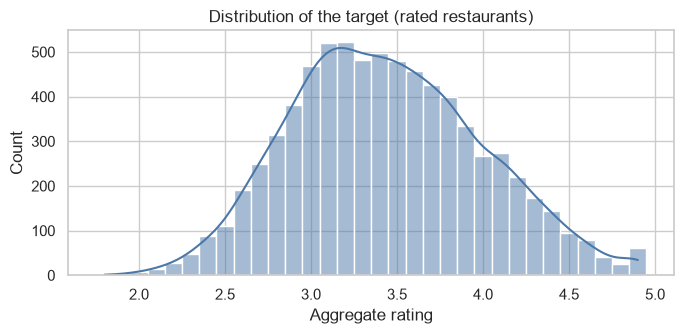

In [4]:
rated = df[df[TARGET] > 0].reset_index(drop=True)
train_df, test_df = train_test_split(rated, test_size=0.2, random_state=RANDOM_STATE)
print(f"Rated restaurants: {len(rated):,} | train: {len(train_df):,} | test: {len(test_df):,}")
print(f"Target mean/std (train): {train_df[TARGET].mean():.3f} / {train_df[TARGET].std():.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(rated[TARGET], bins=np.arange(1.75, 4.96, 0.1), kde=True, ax=ax, color="#4C78A8")
ax.set(title="Distribution of the target (rated restaurants)", xlabel=TARGET)
plt.tight_layout()
plt.show()

## 3. Feature engineering
- **Categorical:** `Country Code`, `City` (one-hot; rare cities grouped as "infrequent").
- **Cuisines:** multi-hot encoding of the 40 most frequent cuisines (vocabulary learned from training data) plus the number of cuisines.
- **Numeric/binary:** coordinates (a zero longitude/latitude is a placeholder and is treated as missing and median-imputed with a missing-indicator), `Price range`, table booking / online delivery / delivering-now flags, `log(1 + Votes)`, name length, address length.
- **Relative cost:** `Average Cost for two` is in local currencies and not comparable across countries, so it is expressed relative to the **training-set** median cost of the same country (log scale).

In [5]:
def split_cuisines(text):
    return [c.strip() for c in text.split(",") if c.strip()]


def make_features(frame, country_median_cost, fallback_cost):
    cuisines = frame["Cuisines"].fillna("")
    cost_ref = frame["Country Code"].map(country_median_cost).fillna(fallback_cost)
    coords_missing = (frame["Longitude"] == 0) | (frame["Latitude"] == 0)
    return pd.DataFrame(
        {
            "Country Code": frame["Country Code"].astype(str),
            "City": frame["City"].astype(str),
            "Cuisines": cuisines,
            "Longitude": frame["Longitude"].where(~coords_missing),
            "Latitude": frame["Latitude"].where(~coords_missing),
            "Num Cuisines": cuisines.map(lambda s: len(split_cuisines(s))),
            "Price range": frame["Price range"],
            "Relative Cost (log)": np.log1p(frame["Average Cost for two"]) - np.log1p(cost_ref),
            "Has Table booking": (frame["Has Table booking"] == "Yes").astype(int),
            "Has Online delivery": (frame["Has Online delivery"] == "Yes").astype(int),
            "Is delivering now": (frame["Is delivering now"] == "Yes").astype(int),
            "Votes (log)": np.log1p(frame["Votes"]),
            "Name Length": frame["Restaurant Name"].str.len(),
            "Address Length": frame["Address"].str.len(),
        },
        index=frame.index,
    )


def prepare_xy(train_frame, test_frame):
    # Cost reference statistics come from the training frame only.
    medians = train_frame.groupby("Country Code")["Average Cost for two"].median()
    fallback = train_frame["Average Cost for two"].median()
    return (
        make_features(train_frame, medians, fallback),
        train_frame[TARGET],
        make_features(test_frame, medians, fallback),
        test_frame[TARGET],
    )


CAT_COLS = ["Country Code", "City"]
NUMERIC_COLS = [
    "Longitude", "Latitude", "Num Cuisines", "Price range", "Relative Cost (log)",
    "Has Table booking", "Has Online delivery", "Is delivering now",
    "Votes (log)", "Name Length", "Address Length",
]


def make_preprocessor(numeric_cols):
    return ColumnTransformer(
        [
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15), CAT_COLS),
            (
                "cuisine",
                CountVectorizer(tokenizer=split_cuisines, token_pattern=None, lowercase=False,
                                binary=True, max_features=40),
                "Cuisines",
            ),
            (
                "num",
                Pipeline([
                    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scale", StandardScaler()),
                ]),
                numeric_cols,
            ),
        ],
        sparse_threshold=0,
    )


X_train, y_train, X_test, y_test = prepare_xy(train_df, test_df)
print("Feature frame shape:", X_train.shape, "(train),", X_test.shape, "(test)")
display(X_train.head(3))

Feature frame shape: (5922, 14) (train), (1481, 14) (test)


,Country Code,City,Cuisines,Longitude,Latitude,Num Cuisines,Price range,Relative Cost (log),Has Table booking,Has Online delivery,Is delivering now,Votes (log),Name Length,Address Length
210,216,Dalton,"Japanese, Sushi",-84.992,34.760,2,3,0.455,0,0,0,4.984,24,35
2487,1,New Delhi,"Mithai, Street Food",77.230,28.656,2,1,-1.601,0,0,0,2.996,27,73
6309,1,Noida,"Ice Cream, Desserts",77.321,28.567,2,2,0.262,0,1,0,4.522,9,46


## 4. Model comparison
Candidates: a mean-predicting baseline, Linear and Ridge regression, Decision Trees (unpruned and depth-limited),
Random Forest, and Gradient Boosting. Each is scored with 5-fold cross-validation **on the training set** and then
on the held-out test set. Metrics: R², MAE, and RMSE (in rating points).

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def evaluate(name, estimator, numeric_cols=NUMERIC_COLS):
    pipe = Pipeline([("prep", make_preprocessor(numeric_cols)), ("model", estimator)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    pipe.fit(X_train, y_train)
    pred_train, pred_test = pipe.predict(X_train), pipe.predict(X_test)
    row = {
        "Model": name,
        "CV R2 (mean)": cv_r2.mean(),
        "CV R2 (std)": cv_r2.std(),
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": float(np.sqrt(mean_squared_error(y_test, pred_test))),
    }
    return pipe, row


candidates = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": RidgeCV(alphas=np.logspace(-2, 3, 12)),
    "Decision Tree (unpruned)": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Decision Tree (depth 8)": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE
    ),
}

fitted, rows = {}, []
for name, est in candidates.items():
    fitted[name], row = evaluate(name, est)
    rows.append(row)
    print(f"done: {name}")

results = pd.DataFrame(rows)

done: Baseline (mean)
done: Linear Regression
done: Ridge Regression
done: Decision Tree (unpruned)
done: Decision Tree (depth 8)
done: Random Forest
done: Gradient Boosting


### Light hyperparameter tuning (Random Forest)
A small randomized search (3-fold CV, training data only) over tree depth, leaf size and feature fraction.

In [7]:
search = RandomizedSearchCV(
    Pipeline([
        ("prep", make_preprocessor(NUMERIC_COLS)),
        ("model", RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    param_distributions={
        "model__max_depth": [8, 12, 16, None],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": [0.3, 0.5, 0.8, 1.0],
    },
    n_iter=8, cv=3, scoring="r2", random_state=RANDOM_STATE, n_jobs=1,
)
search.fit(X_train, y_train)
best_rf_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Best Random Forest parameters:", best_rf_params)

tuned_name = "Random Forest (tuned)"
fitted[tuned_name], tuned_row = evaluate(
    tuned_name, RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **best_rf_params)
)
results = pd.concat([results, pd.DataFrame([tuned_row])], ignore_index=True)

Best Random Forest parameters: {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 16}


,Model,CV R2 (mean),CV R2 (std),Train R2,Test R2,Test MAE,Test RMSE
0,Random Forest (tuned),0.621,0.021,0.885,0.666,0.237,0.321
1,Gradient Boosting,0.617,0.019,0.679,0.653,0.245,0.328
2,Random Forest,0.610,0.019,0.915,0.660,0.239,0.324
3,Ridge Regression,0.580,0.021,0.604,0.632,0.252,0.338
4,Linear Regression,0.579,0.022,0.606,0.634,0.251,0.337
5,Decision Tree (depth 8),0.528,0.020,0.626,0.573,0.268,0.363
6,Decision Tree (unpruned),0.233,0.028,1.000,0.241,0.347,0.484
7,Baseline (mean),-0.002,0.002,0.000,-0.000,0.455,0.556


Selected model (highest CV R2): Random Forest (tuned)


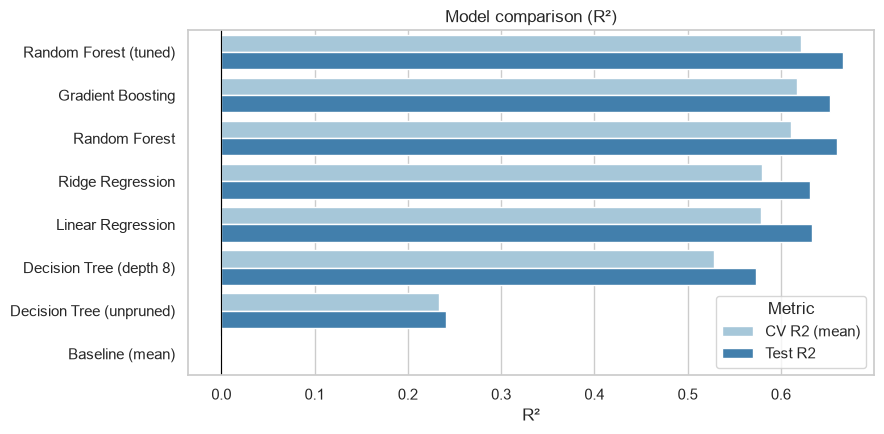

In [ ]:
results = results.sort_values("CV R2 (mean)", ascending=False).reset_index(drop=True)
display(results.round(3))

# Selection uses cross-validation on the training set only; the test set is not used to choose.
best_name = results.loc[0, "Model"]
final_pipe = fitted[best_name]
print(f"Selected model (highest CV R2): {best_name}")

plot_df = results.melt(id_vars="Model", value_vars=["CV R2 (mean)", "Test R2"], var_name="Metric", value_name="R2")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, y="Model", x="R2", hue="Metric", ax=ax, palette=["#9ecae1", "#3182bd"])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Model comparison (R²)", xlabel="R²", ylabel="")
plt.tight_layout()
plt.show()

## 5. Final model — held-out performance

Final model: Random Forest (tuned)
Test R2   : 0.666
Test MAE  : 0.237 rating points
Test RMSE : 0.321 rating points
Share of test predictions within +/-0.5 of the true rating: 88.2%


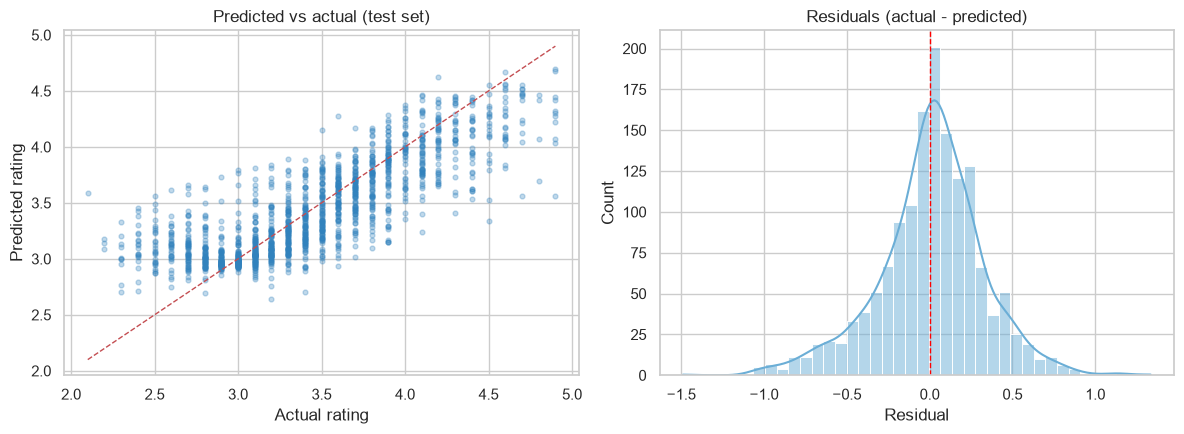

In [ ]:
pred = final_pipe.predict(X_test)
resid = y_test.to_numpy() - pred
within_half = float((np.abs(resid) <= 0.5).mean())

print(f"Final model: {best_name}")
print(f"Test R2   : {r2_score(y_test, pred):.3f}")
print(f"Test MAE  : {mean_absolute_error(y_test, pred):.3f} rating points")
print(f"Test RMSE : {np.sqrt(mean_squared_error(y_test, pred)):.3f} rating points")
print(f"Share of test predictions within +/-0.5 of the true rating: {within_half:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred, alpha=0.3, s=12, color="#3182bd")
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set(title="Predicted vs actual (test set)", xlabel="Actual rating", ylabel="Predicted rating")
sns.histplot(resid, bins=40, kde=True, ax=axes[1], color="#6baed6")
axes[1].axvline(0, color="red", ls="--", lw=1)
axes[1].set(title="Residuals (actual - predicted)", xlabel="Residual")
plt.tight_layout()
plt.show()

### Which features matter? (permutation importance on the test set)
Each raw feature is shuffled in turn; the drop in R² measures how much the model relies on it.

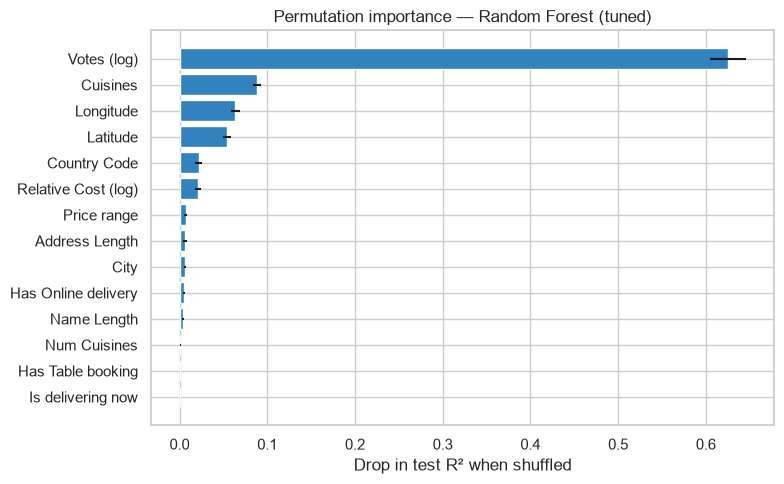

,mean,std
Votes (log),0.625,0.021
Cuisines,0.088,0.005
Longitude,0.063,0.005
Latitude,0.054,0.005
Country Code,0.022,0.004
Relative Cost (log),0.021,0.003
Price range,0.007,0.002
Address Length,0.006,0.002
City,0.006,0.001
Has Online delivery,0.005,0.001


In [ ]:
pi = permutation_importance(
    final_pipe, X_test, y_test, scoring="r2", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1
)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns)
imp = imp.sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color="#3182bd")
ax.set(title=f"Permutation importance — {best_name}", xlabel="Drop in test R² when shuffled")
plt.tight_layout()
plt.show()
display(imp.sort_values("mean", ascending=False).round(4))

## 6. Robustness checks
**(a) Without `Votes`.** Votes accumulate after a restaurant has been visited and rated, so a pre-launch
predictor would not have them. The same model is refit without that feature.

**(b) Including "Not rated" restaurants.** The rating-0 rows are re-added (new split) to show the effect of
treating "no rating yet" as a numeric 0. These test sets differ, so the numbers are **not directly comparable**.

In [ ]:
cols_no_votes = [c for c in NUMERIC_COLS if c != "Votes (log)"]
_, row_nv = evaluate(f"{best_name} (no Votes)", clone(final_pipe.named_steps["model"]), numeric_cols=cols_no_votes)

all_train, all_test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
Xa_tr, ya_tr, Xa_te, ya_te = prepare_xy(all_train, all_test)
pipe_all = clone(final_pipe).fit(Xa_tr, ya_tr)
pred_all = pipe_all.predict(Xa_te)
row_all = {
    "Model": f"{best_name} (incl. Not rated, different test set)",
    "Test R2": r2_score(ya_te, pred_all),
    "Test MAE": mean_absolute_error(ya_te, pred_all),
    "Test RMSE": float(np.sqrt(mean_squared_error(ya_te, pred_all))),
}

robust = pd.DataFrame([
    {"Model": f"{best_name} (rated only, with Votes)", "Test R2": r2_score(y_test, pred),
     "Test MAE": mean_absolute_error(y_test, pred),
     "Test RMSE": float(np.sqrt(mean_squared_error(y_test, pred)))},
    {k: row_nv[k] for k in ["Model", "Test R2", "Test MAE", "Test RMSE"]},
    row_all,
])
display(robust.round(3))

,Model,Test R2,Test MAE,Test RMSE
0,"Random Forest (tuned) (rated only, with Votes)",0.666,0.237,0.321
1,Random Forest (tuned) (no Votes),0.551,0.290,0.373
2,"Random Forest (tuned) (incl. Not rated, differ...",0.964,0.189,0.288


## 7. Summary

In [ ]:
base = results.loc[results["Model"] == "Baseline (mean)"].iloc[0]
top = results.iloc[0]
print(f"Rated restaurants modeled: {len(rated):,} (train {len(train_df):,} / test {len(test_df):,})")
print(f"Baseline (predict the mean): test R2 = {base['Test R2']:.3f}, MAE = {base['Test MAE']:.3f}")
print(f"Selected model by CV: {top['Model']} -> test R2 = {top['Test R2']:.3f}, MAE = {top['Test MAE']:.3f}, RMSE = {top['Test RMSE']:.3f}")
print(f"Train R2 of selected model: {top['Train R2']:.3f}  (gap to CV R2 {top['CV R2 (mean)']:.3f} indicates overfitting if large)")
print("Top 3 features by permutation importance:", ", ".join(imp.sort_values("mean", ascending=False).index[:3]))
print(f"Test R2 without Votes: {row_nv['Test R2']:.3f}")

Rated restaurants modeled: 7,403 (train 5,922 / test 1,481)
Baseline (predict the mean): test R2 = -0.000, MAE = 0.455
Selected model by CV: Random Forest (tuned) -> test R2 = 0.666, MAE = 0.237, RMSE = 0.321
Train R2 of selected model: 0.885  (gap to CV R2 0.621 indicates overfitting if large)
Top 3 features by permutation importance: Votes (log), Cuisines, Longitude
Test R2 without Votes: 0.551


**Notes and limitations**
- Results come from one random 80/20 split plus 5-fold CV on the training portion; they describe this dataset only.
- `Votes` is a strong signal but is only known after a restaurant has been rated; the "no Votes" row above shows performance without it.
- Feature importances show association, not causation.
- Dataset is dominated by one country, so performance on smaller countries is less reliable.